# scMMN — Multi-level Multi-view Network for scRNA-seq Clustering

## Config base path and hyperparameters to run

In [18]:
import os
import sys

sys.path.append(os.path.abspath('..'))

BASE_DIR = '../../data'
dataset = 'yan'

MAX_TOPOLOGY_DIM = 1
TOPO_WEIGHT = 48

# Setup Modules

## 1. Module: `kmeans_gpu`

In [2]:
import torch
import numpy as np

# ---------------------------------------------------------------------------
# kmeans_gpu — GPU-accelerated k-means
# ---------------------------------------------------------------------------

def _km_initialize(X, num_clusters):
    indices = np.random.choice(len(X), num_clusters, replace=False)
    return X[indices]


def kmeans_gpu(X, num_clusters, distance='euclidean', tol=1e-4,
               device=torch.device('cuda')):
    """GPU k-means. Returns (cluster_ids_cpu, centers_cpu)."""
    if distance == 'euclidean':
        pair_dist = _pairwise_distance
    elif distance == 'cosine':
        pair_dist = _pairwise_cosine
    else:
        raise NotImplementedError(f'Unknown distance: {distance}')

    X = X.float().to(device)

    # Best of 20 random initialisations
    dis_min = float('inf')
    best_init = None
    for _ in range(20):
        init = _km_initialize(X, num_clusters)
        dis = pair_dist(X, init, device).sum()
        if dis < dis_min:
            dis_min = dis
            best_init = init

    centers = best_init
    for iteration in range(501):
        dists = pair_dist(X, centers, device)
        labels = torch.argmin(dists, dim=1)
        old_centers = centers.clone()
        for k in range(num_clusters):
            mask = torch.nonzero(labels == k).squeeze().to(device)
            if mask.numel() == 0:
                continue
            centers[k] = torch.index_select(X, 0, mask).mean(0)
        shift = torch.sum(torch.sqrt(((centers - old_centers) ** 2).sum(1)))
        if iteration > 500 or shift ** 2 < tol:
            break

    return labels.cpu(), centers.cpu()


def kmeans_predict_gpu(X, centers, distance='euclidean',
                       device=torch.device('cuda')):
    pair_dist = _pairwise_distance if distance == 'euclidean' else _pairwise_cosine
    X = X.float().to(device)
    return torch.argmin(pair_dist(X, centers, device), dim=1).cpu()


def _pairwise_distance(d1, d2, device=torch.device('cuda')):
    d1, d2 = d1.to(device), d2.to(device)
    return ((d1.unsqueeze(1) - d2.unsqueeze(0)) ** 2).sum(-1).squeeze()


def _pairwise_cosine(d1, d2, device=torch.device('cuda')):
    d1, d2 = d1.to(device), d2.to(device)
    A = d1.unsqueeze(1) / d1.unsqueeze(1).norm(dim=-1, keepdim=True)
    B = d2.unsqueeze(0) / d2.unsqueeze(0).norm(dim=-1, keepdim=True)
    return (1 - (A * B).sum(-1)).squeeze()


print('✓ kmeans_gpu defined')

✓ kmeans_gpu defined


## 2. Module: `utils`

In [3]:
import random
import pickle as pkl
import networkx as nx
import scipy.sparse as sp
from sklearn import metrics
from sklearn.metrics import adjusted_rand_score as ari_score
from sklearn.metrics.cluster import normalized_mutual_info_score as nmi_score

from utils.evaluation import cluster_acc, compute_F1_score

# ---------------------------------------------------------------------------
# utils — data loading, graph preprocessing, clustering evaluation
# ---------------------------------------------------------------------------

def load_graph_data(dataset_name, show_details=False):
    """Load graph dataset from .npy files under dataset/<name>/."""
    load_path = f'dataset/{dataset_name}/{dataset_name}'
    feat  = np.load(load_path + '_feat.npy',  allow_pickle=True)
    label = np.load(load_path + '_label.npy', allow_pickle=True)
    adj   = np.load(load_path + '_adj.npy',   allow_pickle=True)
    if show_details:
        print(f'dataset: {dataset_name}, feat: {feat.shape}, labels: {label.shape}')
        print(f'edges (undirected): {int(np.nonzero(adj)[0].shape[0]/2)}')
        print(f'categories: {max(label)-min(label)+1}')
    return feat, label, adj


def preprocess_graph(adj, layer, norm='sym', renorm=True):
    """Return list of smoothed adjacency matrices (one per GNN layer)."""
    adj  = sp.coo_matrix(adj)
    ident = sp.eye(adj.shape[0])
    adj_ = adj + ident if renorm else adj
    rowsum = np.array(adj_.sum(1))

    if norm == 'sym':
        d_inv_sqrt = sp.diags(np.power(rowsum, -0.5).flatten())
        adj_norm   = adj_.dot(d_inv_sqrt).transpose().dot(d_inv_sqrt).tocoo()
        lap = ident - adj_norm
    else:  # 'left'
        d_inv = sp.diags(np.power(rowsum, -1.).flatten())
        adj_norm = d_inv.dot(adj_).tocoo()
        lap = ident - adj_norm

    adjs = [ident - lap for _ in range(layer)]
    return adjs


def laplacian(adj):
    rowsum = np.array(adj.sum(1))
    lap = sp.diags(rowsum.flatten()) - adj
    return torch.FloatTensor(lap.toarray())


def eva(y_true, y_pred, show_details=True):
    acc = cluster_acc(y_true, y_pred)
    f1_macro, _ = compute_F1_score(y_true, y_pred)

    nmi = nmi_score(y_true, y_pred, average_method='arithmetic')
    ari = ari_score(y_true, y_pred)
    if show_details:
        print(f':acc {acc:.4f}, nmi {nmi:.4f}, ari {ari:.4f}, f1 {f1:.4f}')
    return acc, nmi, ari, f1_macro


def setup_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.benchmark     = False
    torch.backends.cudnn.deterministic = True


def clustering(feature, true_labels, cluster_num):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    pred, _ = kmeans_gpu(feature if isinstance(feature, torch.Tensor)
                         else torch.FloatTensor(feature),
                         cluster_num, distance='euclidean', device=device)
    pred_np = pred.numpy()
    acc, nmi, ari, f1 = eva(true_labels, pred_np, show_details=False)
    ari = metrics.adjusted_rand_score(true_labels, pred_np)
    nmi = metrics.normalized_mutual_info_score(true_labels, pred_np)
    f1  = metrics.cluster.fowlkes_mallows_score(true_labels, pred_np)
    return (round(acc, 4), round(nmi, 4),
            round(ari, 4), round(f1, 4), pred_np)

## 3. Module: `utils_1`

In [4]:
import torch.sparse as ts
import torch.nn.functional as F
from sklearn.model_selection import train_test_split

# ---------------------------------------------------------------------------
# utils_1 — tensor/sparse helpers used by the GCN
# ---------------------------------------------------------------------------

def to_tensor(adj, features, labels=None, device='cpu'):
    if sp.issparse(adj):
        adj = sparse_mx_to_torch_sparse_tensor(adj)
    else:
        adj = torch.FloatTensor(adj)
    features = (sparse_mx_to_torch_sparse_tensor(features)
                if sp.issparse(features)
                else torch.FloatTensor(np.array(features)))
    if labels is None:
        return adj.to(device), features.to(device)
    return adj.to(device), features.to(device), torch.LongTensor(labels).to(device)


def normalize_adj(mx):
    """A' = (D+I)^{-1/2}(A+I)(D+I)^{-1/2}"""
    if not isinstance(mx, sp.lil_matrix):
        mx = mx.tolil()
    if mx[0, 0] == 0:
        mx = mx + sp.eye(mx.shape[0])
    rowsum = np.array(mx.sum(1))
    r_inv  = np.power(rowsum, -0.5).flatten()
    r_inv[np.isinf(r_inv)] = 0.
    r_mat  = sp.diags(r_inv)
    return r_mat.dot(mx).dot(r_mat)


def normalize_adj_tensor(adj, sparse=False):
    device = adj.device
    if sparse:
        adj = to_scipy(adj)
        return sparse_mx_to_torch_sparse_tensor(normalize_adj(adj)).to(device)
    mx = adj + torch.eye(adj.shape[0]).to(device)
    rowsum = mx.sum(1)
    r_inv  = rowsum.pow(-0.5).flatten()
    r_inv[torch.isinf(r_inv)] = 0.
    r_mat  = torch.diag(r_inv)
    return r_mat @ mx @ r_mat


def sparse_mx_to_torch_sparse_tensor(sparse_mx):
    sparse_mx = sparse_mx.tocoo().astype(np.float32)
    rows = torch.LongTensor(sparse_mx.row).unsqueeze(1)
    cols = torch.LongTensor(sparse_mx.col).unsqueeze(1)
    idx  = torch.cat((rows, cols), 1)
    vals = torch.FloatTensor(sparse_mx.data)
    return torch.sparse.FloatTensor(idx.t(), vals,
                                    torch.Size(sparse_mx.shape))


def is_sparse_tensor(t):
    return t.layout == torch.sparse_coo


def to_scipy(tensor):
    if is_sparse_tensor(tensor):
        v = tensor._values(); i = tensor._indices()
    else:
        i = tensor.nonzero().t(); v = tensor[i[0], i[1]]
    return sp.csr_matrix((v.cpu().numpy(), i.cpu().numpy()),
                         shape=tensor.shape)


def accuracy(output, labels):
    if type(labels) is not torch.Tensor:
        labels = torch.LongTensor(labels)
    preds = output.max(1)[1].type_as(labels)
    return preds.eq(labels).double().sum() / len(labels)


print('✓ utils_1 defined')

✓ utils_1 defined


## 4. Module: `model` (MLP + soft-assignment head)

In [5]:
import torch.nn as nn
from torch.nn import Parameter

# ---------------------------------------------------------------------------
# model — auxiliary MLP used to merge dual-view embeddings
# ---------------------------------------------------------------------------

class MyModel(nn.Module):
    """Two-branch linear encoder with soft DEC-style assignment head."""

    def __init__(self, dims):
        """
        dims: [input_dim, output_dim]  (e.g. [cluster_num*2, 500])
        """
        super().__init__()
        self.layers1 = nn.Linear(dims[0], dims[1])
        self.layers2 = nn.Linear(dims[0], dims[1])
        self.mu      = Parameter(torch.Tensor(dims[0], dims[1]))
        self.alpha   = 1.0

    def forward(self, x, is_train=True, sigma=0.01):
        out1 = F.normalize(self.layers1(x), dim=1, p=2)
        out2 = self.layers2(x)
        if is_train:
            out2 = F.normalize(out2, dim=1, p=2) + \
                   torch.normal(0, torch.ones_like(out2) * sigma).to(x.device)
        else:
            out2 = F.normalize(out2, dim=1, p=2)
        return out1

    def soft_assign(self, z):
        q = 1.0 / (1.0 + ((z.unsqueeze(1) - self.mu) ** 2).sum(2) / self.alpha)
        q = q ** ((self.alpha + 1.0) / 2.0)
        return (q.t() / q.sum(1)).t()

    def target_distribution(self, q):
        p = q ** 2 / q.sum(0)
        return (p.t() / p.sum(1)).t()


print('✓ MyModel defined')

✓ MyModel defined


## 5. Module: `gcn` (2-layer GCN)

In [6]:
import math
from copy import deepcopy
from torch.nn.parameter import Parameter as TorchParam
from torch.nn.modules.module import Module
import torch.optim as optim

# ---------------------------------------------------------------------------
# gcn — 2-layer Graph Convolutional Network
# ---------------------------------------------------------------------------

class GraphConvolution(Module):
    """Simple GCN layer (Kipf & Welling 2017)."""

    def __init__(self, in_features, out_features, with_bias=True):
        super().__init__()
        self.in_features  = in_features
        self.out_features = out_features
        self.weight = TorchParam(torch.DoubleTensor(in_features, out_features))
        self.bias   = TorchParam(torch.FloatTensor(out_features)) if with_bias else None
        if self.bias is None:
            self.register_parameter('bias', None)
        self.reset_parameters()

    def reset_parameters(self):
        stdv = 1. / math.sqrt(self.weight.size(1))
        self.weight.data.uniform_(-stdv, stdv)
        if self.bias is not None:
            self.bias.data.uniform_(-stdv, stdv)

    def forward(self, inp, adj):
        # OPTIMIZATION: Keep adjacency in float32, avoid unnecessary .double() conversion
        # Handle both dense and sparse adjacency matrices
        if is_sparse_tensor(adj):
            # For sparse tensors, convert to float32 if needed and use torch.sparse.mm
            adj = adj.float()
            inp_f32 = inp.float()
            supp = torch.spmm(inp_f32, self.weight.float())
            out = torch.sparse.mm(adj, supp)
        else:
            # For dense tensors, use the original logic but keep float32
            inp_f32 = inp.float()
            supp = torch.spmm(inp_f32, self.weight.float()) if inp_f32.data.is_sparse \
                   else torch.mm(inp_f32, self.weight.float())
            out = torch.spmm(adj.float(), supp)
        
        # Ensure bias is added correctly
        if self.bias is not None:
            return out + self.bias.float()
        return out

    def __repr__(self):
        return (f'{self.__class__.__name__} '
                f'({self.in_features} -> {self.out_features})')


class GCN(nn.Module):
    """2-layer GCN used as the dual-view encoder backbone in scMMN."""

    def __init__(self, nfeat, nhid, nclass, dropout=0.5, lr=0.01,
                 weight_decay=5e-4, with_relu=True, with_bias=True, device=None):
        super().__init__()
        assert device is not None, "Please specify 'device'!"
        self.device  = device
        self.nfeat   = nfeat
        self.nclass  = nclass
        self.hidden_sizes = [nhid]
        self.gc1 = GraphConvolution(nfeat, nhid, with_bias=with_bias)
        self.gc2 = GraphConvolution(nhid, nclass, with_bias=with_bias)
        self.dropout     = dropout
        self.lr          = lr
        self.weight_decay = 0 if not with_relu else weight_decay
        self.with_relu   = with_relu
        self.with_bias   = with_bias
        # state
        self.output = self.best_model = self.best_output = None
        self.adj_norm = self.features = self.labels = None

    def forward(self, x, adj):
        x = F.relu(self.gc1(x, adj)) if self.with_relu else self.gc1(x, adj)
        x = F.dropout(x, self.dropout, training=self.training)
        x = self.gc2(x, adj)
        return F.log_softmax(x, dim=1)

    def initialize(self):
        self.gc1.reset_parameters()
        self.gc2.reset_parameters()

    def fit(self, features, adj, labels, idx_train, idx_val=None,
            train_iters=200, initialize=True, verbose=False,
            normalize=True, patience=500):
        self.device = self.gc1.weight.device
        if initialize:
            self.initialize()
        if not isinstance(features, torch.Tensor):
            features, adj, labels = to_tensor(features, adj, labels, device=self.device)
        else:
            features = features.to(self.device)
            adj      = adj.to(self.device)
            labels   = labels.to(self.device)
        if normalize:
            adj_norm = normalize_adj_tensor(adj, sparse=is_sparse_tensor(adj))
        else:
            adj_norm = adj
        self.adj_norm = adj_norm
        self.features = features
        self.labels   = labels
        if idx_val is None:
            self._train_without_val(labels, idx_train, train_iters, verbose)
        else:
            self._train_with_val(labels, idx_train, idx_val, train_iters, verbose)

    def _train_without_val(self, labels, idx_train, train_iters, verbose):
        self.train()
        opt = optim.Adam(self.parameters(), lr=self.lr,
                         weight_decay=self.weight_decay)
        for i in range(train_iters):
            opt.zero_grad()
            out  = self.forward(self.features, self.adj_norm)
            loss = F.nll_loss(out[idx_train], labels[idx_train])
            loss.backward(); opt.step()
            if verbose and i % 10 == 0:
                print(f'Epoch {i}, loss: {loss.item():.4f}')
        self.eval()
        self.output = self.forward(self.features, self.adj_norm)

    def _train_with_val(self, labels, idx_train, idx_val, train_iters, verbose):
        opt = optim.Adam(self.parameters(), lr=self.lr,
                         weight_decay=self.weight_decay)
        best_loss_val = best_acc_val = 0
        weights = None
        for i in range(train_iters):
            self.train(); opt.zero_grad()
            out  = self.forward(self.features, self.adj_norm)
            loss = F.nll_loss(out[idx_train], labels[idx_train])
            loss.backward(); opt.step()
            self.eval()
            out      = self.forward(self.features, self.adj_norm)
            loss_val = F.nll_loss(out[idx_val], labels[idx_val])
            acc_val  = accuracy(out[idx_val], labels[idx_val])
            if best_loss_val == 0 or best_loss_val > loss_val:
                best_loss_val = loss_val
                weights = deepcopy(self.state_dict())
            if best_acc_val == 0 or acc_val > best_acc_val:
                best_acc_val = acc_val
                weights = deepcopy(self.state_dict())
        if weights:
            self.load_state_dict(weights)

    def predict(self, features=None, adj=None):
        self.eval()
        if features is None and adj is None:
            return self.forward(self.features, self.adj_norm)
        if not isinstance(adj, torch.Tensor):
            features, adj = to_tensor(features, adj, device=self.device)
        self.features = features
        self.adj_norm = normalize_adj_tensor(
            adj, sparse=is_sparse_tensor(adj))
        return self.forward(self.features, self.adj_norm)


print('✓ GCN defined')

✓ GCN defined


## 6. Module: `graph_function` (KNN + DM adjacency)

In [7]:
import pandas as pd
from scipy.sparse import find, csr_matrix
from sklearn.neighbors import kneighbors_graph

# ---------------------------------------------------------------------------
# graph_function — KNN and Diffusion Map adjacency construction
# ---------------------------------------------------------------------------

def degree_power(A, k):
    degrees = np.power(np.array(A.sum(1)), k).flatten()
    degrees[np.isinf(degrees)] = 0.
    return sp.diags(degrees) if sp.issparse(A) else np.diag(degrees)


def norm_adj(A):
    D_inv_sqrt = degree_power(A, -0.5)
    return D_inv_sqrt.dot(A).dot(D_inv_sqrt)


def _convert_to_affinity(adj, scaling_factors, with_self_loops=False):
    N = adj.shape[0]
    rows, cols, dists = find(adj)
    dists = (dists ** 2 / (2 * scaling_factors.values[rows] ** 2) +
             dists ** 2 / (2 * scaling_factors.values[cols] ** 2))
    return csr_matrix((np.exp(-dists), (rows, cols)), shape=[N, N])


def get_adj_DM(data, k=15):
    """Diffusion-Map–style adaptive affinity adjacency."""
    print('Nearest neighbour computation (DM)...')
    dist = kneighbors_graph(data, data.shape[0], mode='distance',
                            metric='euclidean', include_self=True)
    dist_arr = dist.toarray()
    adaptive_k = int(np.floor(k))
    sf = pd.Series([np.sort(dist_arr[i])[adaptive_k]
                    for i in range(data.shape[0])])
    nn_aff = _convert_to_affinity(dist, sf)
    adj = nn_aff.toarray()
    idx = adj.argsort()
    rep = adj.shape[1] + 1 - k
    for i in range(idx.shape[0]):
        adj[i, idx[i, :rep]] = 0
        adj[i, i] = 1
    adj[adj > 0] = 1
    return adj, norm_adj(adj)


def get_adj(data, k=15):
    """Plain KNN connectivity adjacency."""
    A = kneighbors_graph(data, k, mode='connectivity',
                         metric='euclidean', include_self=True)
    adj = A.toarray()
    return adj, norm_adj(adj)


print('✓ graph_function defined')

✓ graph_function defined


## 7. Module: `preprocessH5`

In [8]:
import h5py
import scanpy as sc
from sklearn.preprocessing import LabelEncoder

# ---------------------------------------------------------------------------
# preprocessH5 — H5 file I/O + scanpy normalisation pipeline
# ---------------------------------------------------------------------------

class _dotdict(dict):
    __getattr__ = dict.get
    __setattr__ = dict.__setitem__
    __delattr__ = dict.__delitem__


def _decode(data):
    if data.dtype.type is np.bytes_:
        return np.vectorize(lambda x: x.decode('utf-8'))(data)
    return data


def _read_clean(data):
    assert isinstance(data, np.ndarray)
    data = _decode(data)
    return data.flat[0] if data.size == 1 else data


def _dict_from_group(group):
    d = _dotdict()
    for key in group:
        val = (_dict_from_group(group[key])
               if isinstance(group[key], h5py.Group)
               else _read_clean(group[key][...]))
        d[key] = val
    return d


def _read_data(filename):
    import scipy as scipy_
    with h5py.File(filename, 'r') as f:
        obs = pd.DataFrame(_dict_from_group(f['obs']))
        var = pd.DataFrame(_dict_from_group(f['var']))
        uns = _dict_from_group(f['uns'])
        eh  = f['exprs']
        if isinstance(eh, h5py.Group):
            mat = scipy_.sparse.csr_matrix(
                (eh['data'][...], eh['indices'][...], eh['indptr'][...]),
                shape=eh['shape'][...])
        else:
            mat = eh[...].astype(np.float32)
    return mat, obs, var, uns


def _prepro(filename):
    mat, obs, var, uns = _read_data(filename)
    X = np.array(mat.toarray() if hasattr(mat, 'toarray') else mat)
    cell_name  = np.array(obs['cell_type1'])
    cell_type, cell_label = np.unique(cell_name, return_inverse=True)
    return X, cell_label


def _pre_normalize(adata, copy=True, highly_genes=None,
                   filter_min_counts=True, size_factors=True,
                   normalize_input=True, logtrans_input=True):
    if isinstance(adata, sc.AnnData):
        if copy:
            adata = adata.copy()
    elif isinstance(adata, str):
        adata = sc.read(adata)
    else:
        raise NotImplementedError
    if filter_min_counts:
        sc.pp.filter_genes(adata, min_counts=1)
        sc.pp.filter_cells(adata, min_counts=1)
    if size_factors or normalize_input or logtrans_input:
        adata.raw = adata.copy()
    else:
        adata.raw = adata
    if size_factors:
        sc.pp.normalize_per_cell(adata)
        adata.obs['size_factors'] = (adata.obs.n_counts /
                                     np.median(adata.obs.n_counts))
    else:
        adata.obs['size_factors'] = 1.0
    if logtrans_input:
        sc.pp.log1p(adata)
    if highly_genes is not None:
        sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3,
                                    min_disp=0.5,
                                    n_top_genes=highly_genes, subset=True)
    if normalize_input:
        sc.pp.scale(adata)
    return adata


def load_h5(filename, n_gene=None):
    """Load & preprocess an H5 file (legacy scMMN format)."""
    X, Y    = _prepro(filename)
    adata   = sc.AnnData(X)
    adata.obs['Group'] = Y
    adata   = _pre_normalize(adata, copy=True, highly_genes=n_gene,
                             size_factors=True, normalize_input=True,
                             logtrans_input=True)
    X       = adata.X.astype(np.float32)
    Y       = np.array(adata.obs['Group'])
    sf      = np.array(adata.obs.size_factors).reshape(-1, 1).astype(np.float32)
    n_clust = int(max(Y) - min(Y) + 1)
    return X, Y, X.copy(), sf, n_clust


# ---- Alternative loader for the simpler X/Y HDF5 layout -----------------

def load_h5_xy(data_path, nb_genes=2000):
    """
    Load an H5 file with datasets named 'X' and 'Y'.
    Applies scanpy normalisation (filter → normalize → log1p → HVG → scale).
    Returns (X_processed, Y_int_labels).
    """
    with h5py.File(data_path, 'r') as f:
        X = np.array(f['X']).astype('float32')
        Y = np.array(f['Y'])
    if Y.dtype != 'int64':
        Y = LabelEncoder().fit_transform(Y)
    print(f'Loaded {X.shape[0]} cells × {X.shape[1]} genes')
    adata = sc.AnnData(X)
    if nb_genes and nb_genes < X.shape[1]:
        sc.pp.filter_genes(adata, min_cells=1)
        sc.pp.normalize_total(adata, exclude_highly_expressed=True)
        sc.pp.log1p(adata)
        sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3,
                                    min_disp=0.5,
                                    n_top_genes=nb_genes, subset=True)
    else:
        sc.pp.normalize_total(adata, exclude_highly_expressed=True)
        sc.pp.log1p(adata)
    X = adata.X.astype('float32')
    print(f'After preprocessing: {X.shape[0]} cells × {X.shape[1]} genes')
    return X, Y


print('✓ preprocessH5 defined')

✓ preprocessH5 defined


## 8. scMMN Helpers + Train function

The `Train` function signature:

```python
Train(model, MLp,
      inx1, inx2, adj1, adj2,
      target1, target2,
      true_labels, cluster_num,
      args,
      topo_loss_weight=0,
      topo_start_epoch_ratio=0.5,
      topo_batch_size=64,
      topo_max_dim=1)
```

`topo_loss_weight` controls the weight of the **topology signature loss** applied to *all four contrastive views* (z1_knn, z2_knn, z1_DM, z2_DM).  
Set it to `0` (default) to replicate the original scMMN without topology loss.

In [9]:
from tqdm import tqdm
from numpy import mean as np_mean
from sklearn.decomposition import PCA
from topology_signature import TopologySignatureLoss

# ---------------------------------------------------------------------------
# Auxiliary functions
# ---------------------------------------------------------------------------

def build_knn_graph(X, k):
    from sklearn.neighbors import kneighbors_graph
    return kneighbors_graph(X, k, mode='connectivity',
                            metric='cosine', include_self=True)


def sim_fn(z1: torch.Tensor, z2: torch.Tensor) -> torch.Tensor:
    """Cosine similarity matrix."""
    return torch.mm(F.normalize(z1), F.normalize(z2).t())


def semi_loss_fn(z1: torch.Tensor, z2: torch.Tensor,
                 tau: float = 10) -> torch.Tensor:
    """InfoNCE-style contrastive loss."""
    f = lambda x: torch.exp(x / tau)
    rs = f(sim_fn(z1, z1))
    bs = f(sim_fn(z1, z2))
    return -torch.log(
        bs.diag() / (rs.sum(1) + bs.sum(1) - rs.diag()))


def contrastive_loss(z1, z2, tau=10):
    l1 = semi_loss_fn(z1, z2, tau)
    l2 = semi_loss_fn(z2, z1, tau)
    return ((l1 + l2) * 0.5).mean()


# ---------------------------------------------------------------------------
# Train
# ---------------------------------------------------------------------------

def Train(
    model, MLp, inx1, inx2, adj1, adj2, target1, target2, 
    true_labels, cluster_num, args, optimizer=None,
    topo_loss_weight: float = 0, topo_start_epoch_ratio: float = 0.5,
    topo_batch_size: int = 64, topo_max_dim: int = 1, seed: int = 0
):
    setup_seed(seed)
    device = args.device
    topology_loss_fn = TopologySignatureLoss(max_dimension=MAX_TOPOLOGY_DIM)

    # Optimiser
    if optimizer is None:
        optimizer = torch.optim.Adam(
            list(model.parameters()) + list(MLp.parameters()),
            lr=args.lr)

    # OPTIMIZATION: Keep target matrices in float32 (no .double())
    target1 = target1.to(device)
    target2 = target2.to(device)

    topo_start = int(topo_start_epoch_ratio * args.epochs)

    for epoch in tqdm(range(args.epochs), desc=f'Seed {seed}'):
        model.train(); MLp.train()
        optimizer.zero_grad()

        # ---------- Dual-view GCN embeddings ----------
        z1_knn = model(inx1, adj1)
        z2_knn = model(inx2, adj1)
        z1_DM  = model(inx1, adj2)
        z2_DM  = model(inx2, adj2)

        # ---------- Contrastive losses ----------------
        ret_knn = contrastive_loss(z1_knn, z2_knn)
        ret_DM  = contrastive_loss(z1_DM,  z2_DM)

        # ---------- Reconstruction losses -------------
        # OPTIMIZATION: Keep similarity matrices in float32 (no .double())
        S_knn = F.normalize(z1_knn, dim=1) @ F.normalize(z2_knn, dim=1).T
        S_DM  = F.normalize(z1_DM, dim=1) @ F.normalize(z2_DM, dim=1).T
        loss_knn = F.mse_loss(S_knn, target1)
        loss_DM  = F.mse_loss(S_DM,  target2)

        # ---------- Cross-view similarity alignment ---
        loss_sim = F.mse_loss(S_DM, S_knn) + F.mse_loss(S_knn, S_DM)

        # ---------- MLP fusion ------------------------
        z_knn = (z1_knn + z2_knn) * 0.5
        z_DM  = (z1_DM  + z2_DM ) * 0.5
        z_em  = torch.cat([z_knn, z_DM], dim=1).to(torch.float32)
        _     = MLp(z_em, is_train=True, sigma=args.sigma)

        # ---------- Loss weights ----------------------
        alpha_w = 1.0   
        beta_w  = 0.001 
        gamma_w = 0.5   

        loss = ((loss_knn + loss_DM) * alpha_w
                + (ret_knn + ret_DM) * beta_w
                +  loss_sim          * gamma_w)

        # ---------- Topology signature loss -----------
        topo_loss_val = 0.000  # Default to 0 for logging
        
        if topo_loss_weight > 0 and epoch >= topo_start:
            # Dynamically instantiate the topology loss for the KNN views
            # z1_knn acts as the structural anchor (X_tensor)
            
            # Compute cross-view topological alignment
            # Pass the second view (z2) as the target to align with the anchor

            tl = topology_loss_fn.forward_by_batch(z1_knn.to(torch.float32), z2_knn.to(torch.float32), batch_size=64) 
            + topology_loss_fn.forward_by_batch(z1_DM.to(torch.float32), z2_DM.to(torch.float32), batch_size=64)

            topo_loss_val = topo_loss_weight * tl.item()  # Extract the scalar for logging
            loss = loss +  topo_loss_weight * tl

        loss.backward()
        optimizer.step()

        # ---------- Logging every 20 epochs -----------
        if epoch % 20 == 0 and epoch > 900:
            rec_loss_val  = (loss_knn + loss_DM).item()
            cont_loss_val = (ret_knn + ret_DM).item()
            sim_loss_val  = loss_sim.item()
            total_loss    = loss.item()
            
            tqdm.write(
                f"Epoch {epoch:4d} | "
                f"Rec: {rec_loss_val:.4f} | "
                f"Cont: {cont_loss_val:.4f} | "
                f"Sim: {sim_loss_val:.4f} | "
                f"Topo: {topo_loss_val:.4f} | "
                f"Total: {total_loss:.4f}"
            )

    # ---------- Evaluation at Last Epoch --------
    model.eval(); MLp.eval()
    with torch.no_grad():
        zz1_knn = model(inx1, adj1)
        zz2_knn = model(inx2, adj1)
        zz1_DM  = model(inx1, adj2)
        zz2_DM  = model(inx2, adj2)
        hidden  = torch.cat([(zz1_knn + zz2_knn) / 2,
                             (zz1_DM  + zz2_DM ) / 2], dim=1).to(torch.float32)
        z_mlp   = MLp(hidden, is_train=False)

    last_acc, last_nmi, last_ari, last_f1, last_pred = clustering(z_mlp, true_labels, cluster_num)
    
    tqdm.write(f'  acc={last_acc:.2f}  nmi={last_nmi:.2f}  '
               f'ari={last_ari:.2f}  f1={last_f1:.2f}')
    
    return last_acc, last_nmi, last_ari, last_f1, z_mlp, last_pred

def inference(model, MLp, inx1, inx2, adj1, adj2):
    model.eval()
    MLp.eval()
    with torch.no_grad():
        z1_knn = model(inx1, adj1)
        z2_knn = model(inx2, adj1)
        z1_DM  = model(inx1, adj2)
        z2_DM  = model(inx2, adj2)
        hidden = torch.cat([(z1_knn + z2_knn) / 2,
                            (z1_DM  + z2_DM ) / 2], dim=1).to(torch.float32)
        z_mlp  = MLp(hidden, is_train=False)
    return z_mlp


print('✓ Train function defined')

✓ Train function defined


## 9. ▶ Run Experiment — Topology Loss Weight Ablation

Edit the cells below to point to your own `.h5` dataset and choose which topology weights to sweep.

In [14]:
import os
import argparse
import numpy as np
import torch
import scipy.sparse as sp

# ============================================================
# 1. Hyperparameters & Configuration
# ============================================================
args = argparse.Namespace(
    gnnlayers  = 1,
    epochs     = 10,
    dims       = [500],
    lr         = 1e-3,
    sigma      = 0.01,
    device     = torch.device('cuda' if torch.cuda.is_available() else 'cpu'),
)

K_KNN  = 30       # neighbours for KNN graph
K_DM   = 30       # neighbours for DM  graph
N_GENE = 2000     # top highly-variable genes to keep
FIXED_SEED = 42

# ============================================================
# 3. Main Execution Loop
# ============================================================

# ----------------------------------------------------
# Path Resolution & Data Loading
# ----------------------------------------------------
data_path = f"{BASE_DIR}/{dataset}.h5"

X, Y = load_h5_xy(data_path, nb_genes=N_GENE)
NUM_CLUSTERS = len(set(Y))
print(f'Clusters: {NUM_CLUSTERS}')

# ----------------------------------------------------
# Build Dual Graphs (KNN & DM)
# ----------------------------------------------------
def process_data(X: np.ndarray):
    _, DM_adj_n = get_adj_DM(X, k=K_DM)
    KNN_raw = build_knn_graph(X, K_KNN)

    adj1 = sp.csr_matrix(KNN_raw)
    adj2 = sp.csr_matrix(DM_adj_n)

    # Remove self-loops before smoothing
    adj1 = adj1 - sp.dia_matrix((adj1.diagonal()[np.newaxis, :], [0]), shape=adj1.shape)
    adj1.eliminate_zeros()
    adj2 = adj2 - sp.dia_matrix((adj2.diagonal()[np.newaxis, :], [0]), shape=adj2.shape)
    adj2.eliminate_zeros()

    adj_norm_s1 = preprocess_graph(adj1, args.gnnlayers, norm='sym', renorm=True)
    adj_norm_s2 = preprocess_graph(adj2, args.gnnlayers, norm='sym', renorm=True)

    sm1 = sp.csr_matrix(X).toarray()
    sm2 = sp.csr_matrix(X).toarray()
    for a in adj_norm_s1: sm1 = a.dot(sm1)
    for a in adj_norm_s2: sm2 = a.dot(sm2)

    # ----------------------------------------------------
    # Prepare Tensors
    # ----------------------------------------------------
    inx1 = torch.FloatTensor(sm1).to(args.device)
    inx2 = torch.FloatTensor(sm2).to(args.device)

    # OPTIMIZATION: Convert to sparse tensors (significant VRAM savings)
    # Create sparse tensors from scipy sparse matrices
    def csr_to_sparse_tensor(csr_mat, device):
        coo = csr_mat.tocoo()
        indices = torch.LongTensor([coo.row, coo.col])
        values = torch.FloatTensor(coo.data)
        return torch.sparse.FloatTensor(indices, values, torch.Size(coo.shape)).to(device)
    
    adj1_t = csr_to_sparse_tensor(adj1, args.device)
    adj2_t = csr_to_sparse_tensor(adj2, args.device)

    # Keep targets in float32 (they are used only for loss computation, not as dense operations)
    target1 = torch.FloatTensor((adj1 + sp.eye(adj1.shape[0])).toarray())
    target2 = torch.FloatTensor((adj2 + sp.eye(adj2.shape[0])).toarray())

    return inx1, inx2, adj1_t, adj2_t, target1, target2

inx1, inx2, adj1_t, adj2_t, target1, target2 = process_data(X)
print('Graph construction and tensors ready.')
print(f'adj1_t sparsity: {adj1_t._nnz()} non-zero elements (shape: {adj1_t.shape})')
print(f'adj2_t sparsity: {adj2_t._nnz()} non-zero elements (shape: {adj2_t.shape})')

# ============================================================
# RUN 1: WITHOUT TOPOLOGY LOSS
# ============================================================
# print(f"\n[{dataset}] Training WITHOUT Topo loss")
# gcn_model_1 = GCN(nfeat=X.shape[1], nhid=64, nclass=NUM_CLUSTERS, dropout=0.2, device=args.device).to(args.device)
# mlp_model_1 = MyModel([NUM_CLUSTERS * 2] + args.dims).to(args.device)
# opt_1 = torch.optim.Adam(list(gcn_model_1.parameters()) + list(mlp_model_1.parameters()), lr=args.lr)

# acc_1, nmi_1, ari_1, f1_1, _, _ = Train(
#     model=gcn_model_1, MLp=mlp_model_1, inx1=inx1, inx2=inx2, 
#     adj1=adj1_t, adj2=adj2_t, target1=target1, target2=target2,
#     true_labels=Y, cluster_num=NUM_CLUSTERS, args=args, optimizer=opt_1,
#     topo_loss_weight=0, topo_start_epoch_ratio=0.8, topo_batch_size=64, topo_max_dim=1, seed=FIXED_SEED
# )

# # ============================================================
# # RUN 2: WITH TOPOLOGY LOSS
# # ============================================================
# print(f"\n[{dataset}] Training WITH Topo loss (Weight: {topo_weight_loss})")
# gcn_model_2 = GCN(nfeat=X.shape[1], nhid=64, nclass=NUM_CLUSTERS, dropout=0.2, device=args.device).to(args.device)
# mlp_model_2 = MyModel([NUM_CLUSTERS * 2] + args.dims).to(args.device)
# opt_2 = torch.optim.Adam(list(gcn_model_2.parameters()) + list(mlp_model_2.parameters()), lr=args.lr)

# acc_2, nmi_2, ari_2, f1_2, _, _ = Train(
#     model=gcn_model_2, MLp=mlp_model_2, inx1=inx1, inx2=inx2, 
#     adj1=adj1_t, adj2=adj2_t, target1=target1, target2=target2,
#     true_labels=Y, cluster_num=NUM_CLUSTERS, args=args, optimizer=opt_2,
#     topo_loss_weight=topo_weight_loss, topo_start_epoch_ratio=0.8, topo_batch_size=64, topo_max_dim=1, seed=FIXED_SEED
# )

Loaded 90 cells × 20214 genes
After preprocessing: 90 cells × 2000 genes
Clusters: 7
Nearest neighbour computation (DM)...
Graph construction and tensors ready.
adj1_t sparsity: 2610 non-zero elements (shape: torch.Size([90, 90]))
adj2_t sparsity: 2530 non-zero elements (shape: torch.Size([90, 90]))


## Robustness Evaluation
**Strategy**: attack the input data (gene matrix or adjacency matrix) then performing end-to-end training

### Prepare util functions

In [20]:
from utils.evaluation import cluster_acc
from sklearn.preprocessing import normalize as sklearn_normalize

device = args.device

def train_model(inx1, inx2, adj1_t, adj2_t, target1, target2, use_topo: bool):
    gcn_model = GCN(nfeat=X.shape[1], nhid=64, nclass=NUM_CLUSTERS, dropout=0.2, device=args.device).to(args.device)
    mlp_model = MyModel([NUM_CLUSTERS * 2] + args.dims).to(args.device)
    opt_1 = torch.optim.Adam(list(gcn_model.parameters()) + list(mlp_model.parameters()), lr=args.lr)

    topo_weight_loss = TOPO_WEIGHT if use_topo else 0.0

    acc, nmi, ari, f1, _, _ = Train(
        model=gcn_model, MLp=mlp_model, inx1=inx1, inx2=inx2, 
        adj1=adj1_t, adj2=adj2_t, target1=target1, target2=target2,
        true_labels=Y, cluster_num=NUM_CLUSTERS, args=args, optimizer=opt_1,
        topo_loss_weight=topo_weight_loss, topo_start_epoch_ratio=0.8, topo_batch_size=64, topo_max_dim=1, seed=FIXED_SEED
    )

    return nmi, ari

### A. Dropout event in gene expression matrix

Nearest neighbour computation (DM)...


Seed 42: 100%|██████████| 10/10 [00:00<00:00, 85.73it/s]


  acc=0.64  nmi=0.73  ari=0.67  f1=0.74


Seed 42: 100%|██████████| 10/10 [00:00<00:00, 63.41it/s]


  acc=0.46  nmi=0.67  ari=0.40  f1=0.52
Dropout Noise Level: 0.00 | Model 1 NMI: 0.7318 | Model 1 ARI: 0.6668 | Model 2 NMI: 0.6736 | Model 2 ARI: 0.3981
Nearest neighbour computation (DM)...


...

  acc=0.69  nmi=0.76  ari=0.71  f1=0.77
Dropout Noise Level: 0.40 | Model 1 NMI: 0.6590 | Model 1 ARI: 0.4281 | Model 2 NMI: 0.7562 | Model 2 ARI: 0.7087
Nearest neighbour computation (DM)...


Seed 42: 100%|██████████| 10/10 [00:00<00:00, 71.17it/s]


  acc=0.70  nmi=0.72  ari=0.69  f1=0.75


Seed 42: 100%|██████████| 10/10 [00:00<00:00, 72.88it/s]


  acc=0.68  nmi=0.72  ari=0.67  f1=0.74
Dropout Noise Level: 0.50 | Model 1 NMI: 0.7231 | Model 1 ARI: 0.6875 | Model 2 NMI: 0.7166 | Model 2 ARI: 0.6683


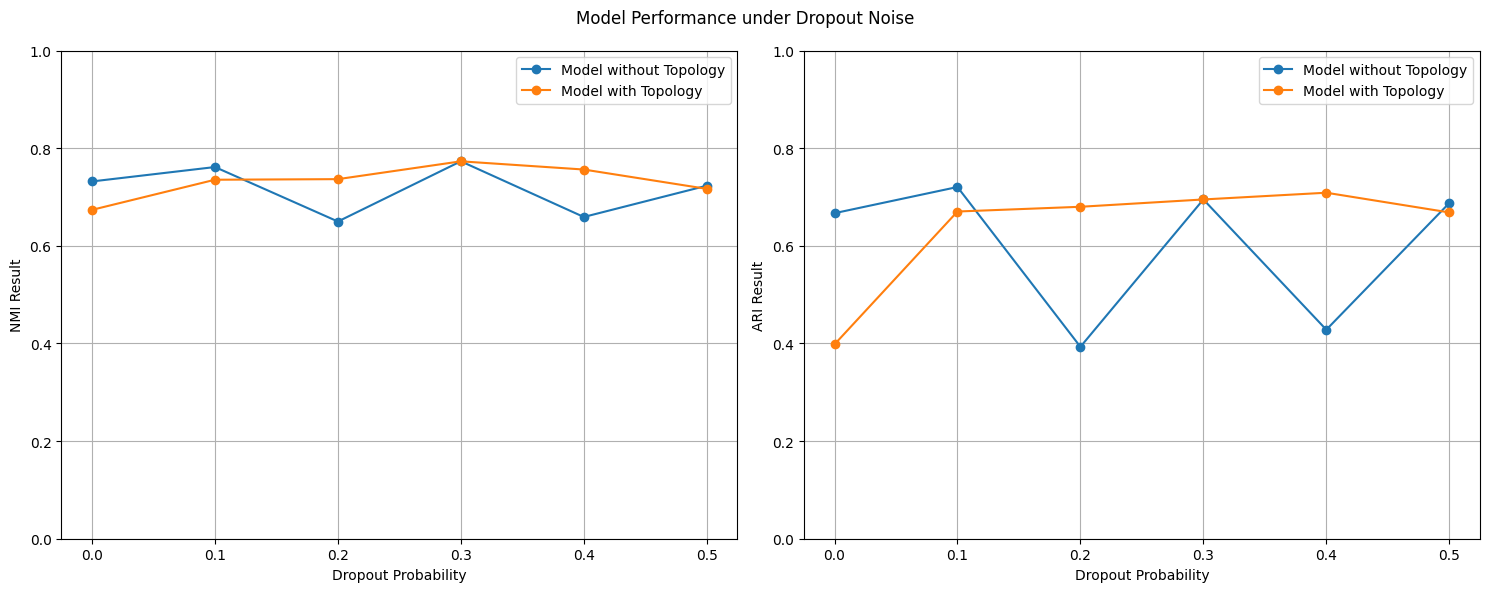

In [25]:
from utils.perturbation import dropout_event

# Testing with dropout_event first
drop_prob = np.arange(0, 0.6, 0.1)

nmi_scores_1 = []
ari_scores_1 = []

nmi_scores_2 = []
ari_scores_2 = []

for prob in drop_prob:
    x_noisy = dropout_event(torch.from_numpy(X), prob)
    inx1, inx2, adj1_t, adj2_t, target1, target2 = process_data(x_noisy.numpy())

    nmi_1, ari_1 = train_model(inx1, inx2, adj1_t, adj2_t, target1, target2, use_topo=False)
    nmi_2, ari_2 = train_model(inx1, inx2, adj1_t, adj2_t, target1, target2, use_topo=True)

    nmi_scores_1.append(nmi_1)
    ari_scores_1.append(ari_1)
    nmi_scores_2.append(nmi_2)
    ari_scores_2.append(ari_2)
    print(f"Dropout Noise Level: {prob:.2f} | Model 1 NMI: {nmi_1:.4f} | Model 1 ARI: {ari_1:.4f} | Model 2 NMI: {nmi_2:.4f} | Model 2 ARI: {ari_2:.4f}")

import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.plot(drop_prob, nmi_scores_1, marker='o', label='Model without Topology')
plt.plot(drop_prob, nmi_scores_2, marker='o', label='Model with Topology')
plt.xlabel('Dropout Probability')
plt.ylabel('NMI Result')
plt.ylim(0, 1)
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(drop_prob, ari_scores_1, marker='o', label='Model without Topology')
plt.plot(drop_prob, ari_scores_2, marker='o', label='Model with Topology')
plt.xlabel('Dropout Probability')
plt.ylabel('ARI Result')
plt.ylim(0, 1)
plt.legend()
plt.grid()

plt.suptitle('Model Performance under Dropout Noise')
plt.tight_layout()

plt.show()

### B. Testing robustness with Gaussian noise in `X_data`

Nearest neighbour computation (DM)...


Seed 42: 100%|██████████| 10/10 [00:00<00:00, 69.41it/s]


  acc=0.68  nmi=0.74  ari=0.68  f1=0.75


Seed 42: 100%|██████████| 10/10 [00:00<00:00, 71.22it/s]


  acc=0.70  nmi=0.76  ari=0.70  f1=0.76
Gaussian Noise Mean: 0.00 | Model 1 NMI: 0.7419 | Model 1 ARI: 0.6823 | Model 2 NMI: 0.7555 | Model 2 ARI: 0.7015
Nearest neighbour computation (DM)...


...

  acc=0.70  nmi=0.76  ari=0.71  f1=0.77
Gaussian Noise Mean: 0.40 | Model 1 NMI: 0.7456 | Model 1 ARI: 0.6865 | Model 2 NMI: 0.7640 | Model 2 ARI: 0.7093
Nearest neighbour computation (DM)...


Seed 42: 100%|██████████| 10/10 [00:00<00:00, 64.97it/s]


  acc=0.63  nmi=0.73  ari=0.66  f1=0.73


Seed 42: 100%|██████████| 10/10 [00:00<00:00, 72.92it/s]


  acc=0.70  nmi=0.75  ari=0.73  f1=0.78
Gaussian Noise Mean: 0.50 | Model 1 NMI: 0.7297 | Model 1 ARI: 0.6623 | Model 2 NMI: 0.7484 | Model 2 ARI: 0.7284


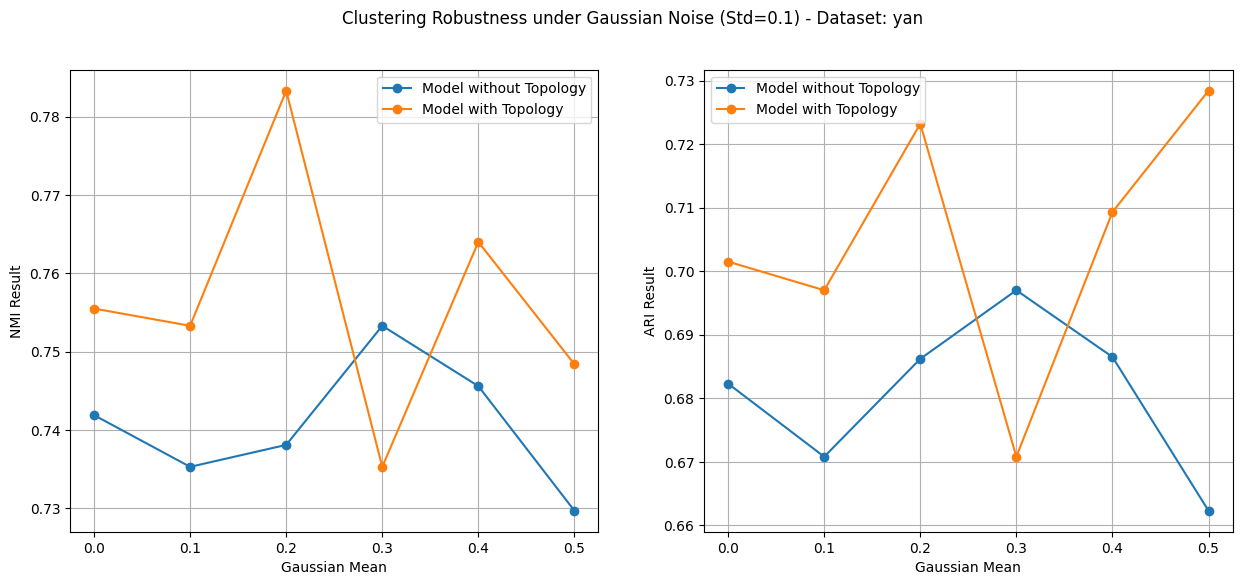

In [27]:
from utils.perturbation import gaussian_noise_event

# Testing with dropout_event first
STD_GAUSSIAN = 0.1
gaussian_mean = np.arange(0, 0.6, 0.1)

nmi_scores_1 = []
ari_scores_1 = []

nmi_scores_2 = []
ari_scores_2 = []

for mean in gaussian_mean:
    x_noisy = gaussian_noise_event(torch.from_numpy(X), mean, std=STD_GAUSSIAN)
    inx1, inx2, adj1_t, adj2_t, _, _ = process_data(x_noisy.numpy())

    nmi_1, ari_1 = train_model(inx1, inx2, adj1_t, adj2_t, target1, target2, use_topo=False)
    nmi_2, ari_2 = train_model(inx1, inx2, adj1_t, adj2_t, target1, target2, use_topo=True)

    nmi_scores_1.append(nmi_1)
    ari_scores_1.append(ari_1)
    nmi_scores_2.append(nmi_2)
    ari_scores_2.append(ari_2)
    print(f"Gaussian Noise Mean: {mean:.2f} | Model 1 NMI: {nmi_1:.4f} | Model 1 ARI: {ari_1:.4f} | Model 2 NMI: {nmi_2:.4f} | Model 2 ARI: {ari_2:.4f}")

import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.plot(gaussian_mean, nmi_scores_1, marker='o', label='Model without Topology')
plt.plot(gaussian_mean, nmi_scores_2, marker='o', label='Model with Topology')
plt.xlabel('Gaussian Mean')
plt.ylabel('NMI Result')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(gaussian_mean, ari_scores_1, marker='o', label='Model without Topology')
plt.plot(gaussian_mean, ari_scores_2, marker='o', label='Model with Topology')
plt.xlabel('Gaussian Mean')
plt.ylabel('ARI Result')
plt.legend()
plt.grid()

plt.suptitle(f'Clustering Robustness under Gaussian Noise (Std={STD_GAUSSIAN}) - Dataset: {dataset}')
plt.show()

### C. Testing robustness with Edge Dropping

Type of adj1_t: <class 'torch.Tensor'>


Seed 42: 100%|██████████| 10/10 [00:00<00:00, 303.44it/s]


  acc=0.63  nmi=0.71  ari=0.64  f1=0.72


Seed 42: 100%|██████████| 10/10 [00:00<00:00, 119.68it/s]


  acc=0.64  nmi=0.63  ari=0.62  f1=0.71
Dropout Edge Level: 0.00 | Model 1 NMI: 0.7059 | Model 1 ARI: 0.6430 | Model 2 NMI: 0.6325 | Model 2 ARI: 0.6243


...

  acc=0.63  nmi=0.59  ari=0.62  f1=0.70
Dropout Edge Level: 0.40 | Model 1 NMI: 0.6139 | Model 1 ARI: 0.4891 | Model 2 NMI: 0.5896 | Model 2 ARI: 0.6196


Seed 42: 100%|██████████| 10/10 [00:00<00:00, 302.40it/s]


  acc=0.61  nmi=0.57  ari=0.58  f1=0.67


Seed 42: 100%|██████████| 10/10 [00:00<00:00, 118.18it/s]


  acc=0.66  nmi=0.61  ari=0.63  f1=0.70
Dropout Edge Level: 0.50 | Model 1 NMI: 0.5657 | Model 1 ARI: 0.5774 | Model 2 NMI: 0.6063 | Model 2 ARI: 0.6251


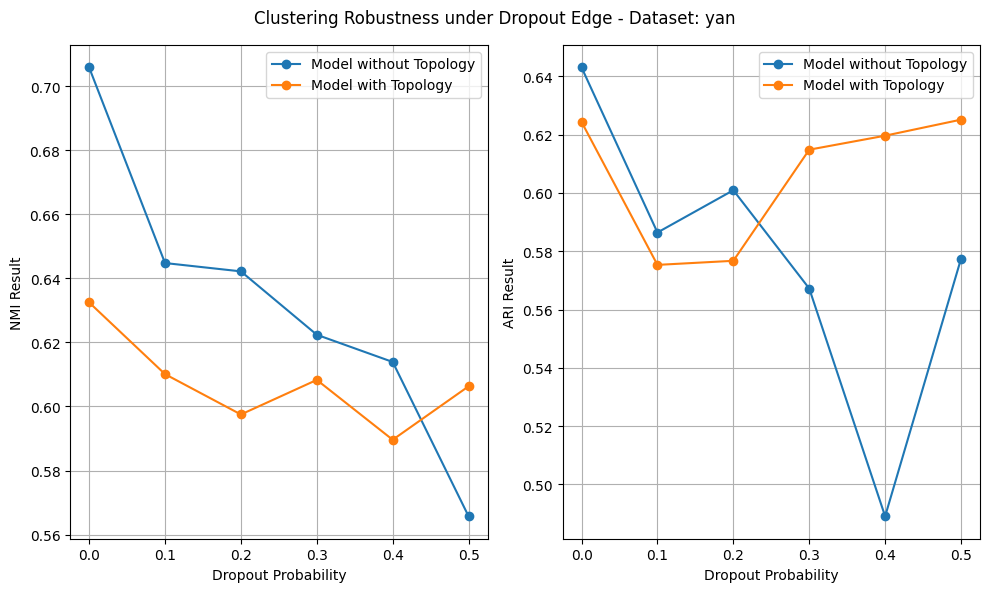

In [34]:
from utils.perturbation import edge_dropout_event

def edge_dropout_event(edge_index: torch.Tensor, drop_prob: float, force_undirected: bool = False):
    """Randomly drop edges from the edge_index with probability drop_prob."""
    row, col = edge_index
    edge_mask = torch.bernoulli(torch.ones(row.size(0), device=edge_index.device) * (1 - drop_prob)).type(torch.bool)

    if force_undirected:
        edge_mask[row > col] = False

    edge_index = edge_index[:, edge_mask]

    if force_undirected:
        edge_index = torch.cat([edge_index, edge_index.flip(0)], dim=1)
        edge_mask = edge_mask.nonzero().repeat((2, 1)).squeeze()

    return edge_index, edge_mask

def to_adj_matrix(edge_index, num_nodes):
    adj = np.zeros((num_nodes, num_nodes), dtype=np.float32)
    adj[edge_index[0], edge_index[1]] = 1.0
    return torch.from_numpy(adj)

# Testing with dropout_event first
edge_drop_prob = np.arange(0, 0.55, 0.1)

nmi_scores_1 = []
ari_scores_1 = []

nmi_scores_2 = []
ari_scores_2 = []

print("Type of adj1_t:", type(adj1_t))

for prob in edge_drop_prob:
    noise_adj_graph_1, _ = edge_dropout_event(edge_index=adj1_t.coalesce().indices(), drop_prob=prob, force_undirected=True)
    noise_adj_graph_2, _ = edge_dropout_event(edge_index=adj2_t.coalesce().indices(), drop_prob=prob, force_undirected=True)

    adj_noisy_1 = to_adj_matrix(noise_adj_graph_1, adj1_t.shape[0])
    adj_noisy_2 = to_adj_matrix(noise_adj_graph_2, adj2_t.shape[0])

    nmi_1, ari_1 = train_model(inx1, inx2, adj_noisy_1, adj_noisy_2, target1, target2, use_topo=False)
    nmi_2, ari_2 = train_model(inx1, inx2, adj_noisy_1, adj_noisy_2, target1, target2, use_topo=True)

    nmi_scores_1.append(nmi_1)
    ari_scores_1.append(ari_1)
    nmi_scores_2.append(nmi_2)
    ari_scores_2.append(ari_2)
    print(f"Dropout Edge Level: {prob:.2f} | Model 1 NMI: {nmi_1:.4f} | Model 1 ARI: {ari_1:.4f} | Model 2 NMI: {nmi_2:.4f} | Model 2 ARI: {ari_2:.4f}")

import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.plot(edge_drop_prob, nmi_scores_1, marker='o', label='Model without Topology')
plt.plot(edge_drop_prob, nmi_scores_2, marker='o', label='Model with Topology')
plt.xlabel('Dropout Probability')
plt.ylabel('NMI Result')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(edge_drop_prob, ari_scores_1, marker='o', label='Model without Topology')
plt.plot(edge_drop_prob, ari_scores_2, marker='o', label='Model with Topology')
plt.xlabel('Dropout Probability')
plt.ylabel('ARI Result')
plt.legend()
plt.grid()

plt.suptitle(f'Clustering Robustness under Dropout Edge - Dataset: {dataset}')

plt.tight_layout()
plt.show()